# Tokenization: From Text to Tokens
### Understanding and implementing Byte Pair Encoding (BPE) from scratch

> **Learning objective:** Understand how raw text is converted into token IDs, why subword tokenization is useful, and how a simple Byte Pair Encoding tokenizer learns a vocabulary by repeatedly merging frequent symbol pairs.

We will build the central ideas using **Python**, inspect results with **Pandas**, and visualize selected patterns with **Matplotlib**. NumPy is available for numerical experiments, but tokenization itself is mostly a string and data-structure problem.

### What this notebook covers

1. Why language models need tokenization
2. Character-level, word-level, and subword tokenization
3. Vocabulary and token IDs
4. Why word-level tokenization has limitations
5. The intuition behind Byte Pair Encoding
6. Pair counting and merge operations
7. Train a small BPE tokenizer from scratch
8. Encode and decode text
9. Explore vocabulary size and token counts
10. Understand unknown words and byte-level tokenization
11. Compare our educational tokenizer with production tokenizers

### Important scope note

The BPE implementation in this notebook is an **educational word-boundary BPE tokenizer**. It starts from characters and uses an end-of-word marker. It teaches the merge algorithm clearly, but it is **not an exact reproduction** of GPT-2, Llama, Qwen, or another production tokenizer. Real tokenizers may use byte-level representations, regex pre-tokenization, special tokens, normalization rules, and implementation-specific details.

## 1. Why do language models need tokenization?

A neural network works with numerical tensors. Raw text such as:

```text
Small language models are interesting.
```

must first be converted into a sequence of discrete units. These units are called **tokens**.

A tokenizer performs two related jobs:

1. **Encoding:** convert text into token IDs.
2. **Decoding:** convert token IDs back into text.

A simplified pipeline is:

```text
Raw text
   │
   ▼
Tokenizer
   │
   ├── Tokens:    ["Small", " language", " models", ...]
   │
   └── Token IDs: [ ... integers ... ]
                    │
                    ▼
               Embedding lookup
                    │
                    ▼
                Transformer
```

The tokenizer defines the model's vocabulary: the set of token units the model can represent directly.

### Why not feed characters directly?

We could. Character-level language models exist. But character sequences can become very long, and the model must learn to combine characters into words and larger patterns.

### Why not use whole words?

We could do that too. But the vocabulary can become enormous, and unseen words become a problem.

Subword tokenization is a practical compromise: frequent words or word fragments can be represented compactly, while less common words can be broken into smaller pieces.

## 2. Three common tokenization strategies

Let's compare three ways to split text.

### A. Character-level tokenization

Each character is a token.

```text
"hello" → ["h", "e", "l", "l", "o"]
```

**Advantages**
- Small base vocabulary.
- Any word can be represented from known characters.

**Disadvantages**
- Long token sequences.
- The model must learn word structure from very small units.

### B. Word-level tokenization

Each word is a token.

```text
"hello world" → ["hello", "world"]
```

**Advantages**
- Shorter sequences for ordinary text.
- Token units often correspond to meaningful words.

**Disadvantages**
- Very large vocabulary.
- Rare words and new names may be unknown.
- Morphological relationships are not shared naturally.

### C. Subword tokenization

Frequent words or word fragments become tokens.

```text
"unhappiness" → ["un", "happiness"]
```

This is only an illustrative split; a real tokenizer may choose different pieces.

**Advantages**
- Balances vocabulary size and sequence length.
- Can represent many unseen words using known pieces.
- Reuses common fragments across related words.

**Disadvantages**
- Token boundaries are not always linguistically intuitive.
- Different tokenizers split the same text differently.

In [1]:

from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


NumPy: 2.3.5
Pandas: 2.2.3


In [2]:
example_text = "small language models learn patterns"

character_tokens = list(example_text)
word_tokens = example_text.split()

comparison = pd.DataFrame([
    {
        "strategy": "Character-level",
        "tokens": character_tokens,
        "token_count": len(character_tokens),
        "unique_units": len(set(character_tokens))
    },
    {
        "strategy": "Word-level",
        "tokens": word_tokens,
        "token_count": len(word_tokens),
        "unique_units": len(set(word_tokens))
    }
])

display(comparison[["strategy", "token_count", "unique_units"]])
print("Character tokens:", character_tokens)
print("Word tokens:     ", word_tokens)

,strategy,token_count,unique_units
0,Character-level,36,14
1,Word-level,5,5


Character tokens: ['s', 'm', 'a', 'l', 'l', ' ', 'l', 'a', 'n', 'g', 'u', 'a', 'g', 'e', ' ', 'm', 'o', 'd', 'e', 'l', 's', ' ', 'l', 'e', 'a', 'r', 'n', ' ', 'p', 'a', 't', 't', 'e', 'r', 'n', 's']
Word tokens:      ['small', 'language', 'models', 'learn', 'patterns']


This simple example shows that tokenization changes the sequence length and the number of distinct units. It does not yet show subword tokenization; we will build that below.

## 3. Vocabulary and token IDs

A **vocabulary** is a mapping between token strings and integer IDs.

For example:

| Token | ID |
|---|---:|
| `small` | 0 |
| `language` | 1 |
| `model` | 2 |

The exact IDs are arbitrary. They are identifiers, not measurements. ID 2 is not inherently greater or more meaningful than ID 0.

Let's build a tiny word-level vocabulary.

In [3]:
sample_text = "small language models are small models"
word_list = sample_text.split()

word_vocabulary = sorted(set(word_list))
word_to_id = {token: idx for idx, token in enumerate(word_vocabulary)}
id_to_word = {idx: token for token, idx in word_to_id.items()}

word_ids = [word_to_id[word] for word in word_list]

display(pd.DataFrame({
    "token": word_vocabulary,
    "token_id": [word_to_id[token] for token in word_vocabulary]
}))

print("Original text:", sample_text)
print("Token IDs:    ", word_ids)

,token,token_id
0,are,0
1,language,1
2,models,2
3,small,3


Original text: small language models are small models
Token IDs:     [3, 1, 2, 0, 3, 2]


In [4]:
def encode_word_level(text, token_to_id):
    return [token_to_id[word] for word in text.split()]


def decode_word_level(ids, id_to_token):
    return " ".join(id_to_token[token_id] for token_id in ids)


encoded = encode_word_level(sample_text, word_to_id)
decoded = decode_word_level(encoded, id_to_word)

print("Encoded:", encoded)
print("Decoded:", decoded)
print("Round trip successful:", decoded == sample_text)

Encoded: [3, 1, 2, 0, 3, 2]
Decoded: small language models are small models
Round trip successful: True


## 4. Why word-level tokenization is not enough

Imagine that our training text contains:

```text
the model learns language
```

The vocabulary might contain `the`, `model`, `learns`, and `language`.

Now suppose we encounter:

```text
the model learns linguistics
```

If `linguistics` was never in the vocabulary, a basic word-level tokenizer cannot represent it unless we add an unknown token such as `[UNK]`.

### Demonstrate the unknown-token problem

In [5]:
training_sentence = "the model learns language"
training_words = sorted(set(training_sentence.split()))

UNK = "[UNK]"
word_to_id_demo = {word: idx for idx, word in enumerate(training_words)}
word_to_id_demo[UNK] = len(word_to_id_demo)

new_sentence = "the model learns linguistics"
new_ids = [
    word_to_id_demo.get(word, word_to_id_demo[UNK])
    for word in new_sentence.split()
]

display(pd.DataFrame({
    "input_word": new_sentence.split(),
    "mapped_token": [
        word if word in word_to_id_demo else UNK
        for word in new_sentence.split()
    ],
    "token_id": new_ids
}))

,input_word,mapped_token,token_id
0,the,the,3
1,model,model,2
2,learns,learns,1
3,linguistics,[UNK],4


The word `linguistics` becomes `[UNK]`. We lose its internal structure.

A subword tokenizer can instead represent an unfamiliar word using pieces it already knows. For example, it might split a word into a prefix, stem, and suffix — though the actual segmentation is learned from data, not manually specified.

This is the motivation for algorithms such as **Byte Pair Encoding (BPE)**.

## 5. Byte Pair Encoding: the intuition

BPE builds a vocabulary by repeatedly merging the most frequent adjacent pair of symbols.

We'll begin with a small corpus:

```text
low
lower
lowest
new
newer
```

Initially, each word is represented as characters plus an end-of-word marker:

```text
l o w </w>
l o w e r </w>
l o w e s t </w>
n e w </w>
n e w e r </w>
```

Then:

1. Count every adjacent symbol pair across the corpus.
2. Find the most frequent pair.
3. Merge that pair into a new symbol.
4. Repeat until we reach the desired number of merges or vocabulary size.

For example, if `l` followed by `o` is frequent, the pair can be merged into `lo`.

Then `lo` followed by `w` might be merged into `low`.

The algorithm gradually learns reusable pieces from frequent patterns.

### Our toy corpus

We will use a small corpus with repeated words so the merge process is easy to inspect. Each word has a frequency. In BPE training, a word that occurs more often contributes more to pair counts.

We append `</w>` so that the tokenizer can learn word-final boundaries. This is one common educational representation; production tokenizers use different conventions.

In [6]:
from collections import Counter

corpus = [
    "low", "low", "low",
    "lower", "lower",
    "lowest",
    "new", "new",
    "newer",
    "wide", "wider"
]

word_frequencies = Counter(corpus)

display(pd.DataFrame(
    sorted(word_frequencies.items()),
    columns=["word", "frequency"]
))

,word,frequency
0,low,3
1,lower,2
2,lowest,1
3,new,2
4,newer,1
5,wide,1
6,wider,1


## 6. Represent words as symbol sequences

The initial alphabet is made from characters. We append `</w>` to each word.

For example:

```text
"low" → ("l", "o", "w", "</w>")
```

We store each unique word once, along with its frequency. This avoids expanding repeated words unnecessarily.

In [7]:
END_OF_WORD = "</w>"

def word_to_symbols(word):
    return tuple(list(word) + [END_OF_WORD])


word_symbols = {
    word: word_to_symbols(word)
    for word in word_frequencies
}

for word, symbols in word_symbols.items():
    print(f"{word:8} -> {symbols}  (frequency={word_frequencies[word]})")

low      -> ('l', 'o', 'w', '</w>')  (frequency=3)
lower    -> ('l', 'o', 'w', 'e', 'r', '</w>')  (frequency=2)
lowest   -> ('l', 'o', 'w', 'e', 's', 't', '</w>')  (frequency=1)
new      -> ('n', 'e', 'w', '</w>')  (frequency=2)
newer    -> ('n', 'e', 'w', 'e', 'r', '</w>')  (frequency=1)
wide     -> ('w', 'i', 'd', 'e', '</w>')  (frequency=1)
wider    -> ('w', 'i', 'd', 'e', 'r', '</w>')  (frequency=1)


## 7. Count adjacent pairs

Suppose a word is represented as:

```text
("l", "o", "w", "</w>")
```

Its adjacent pairs are:

```text
("l", "o")
("o", "w")
("w", "</w>")
```

We count these pairs across all words, weighted by each word's frequency.

### Implement pair counting

In [8]:
def get_pair_counts(symbol_sequences, frequencies):
    pair_counts = Counter()

    for word, symbols in symbol_sequences.items():
        frequency = frequencies[word]

        for index in range(len(symbols) - 1):
            pair = (symbols[index], symbols[index + 1])
            pair_counts[pair] += frequency

    return pair_counts


initial_pair_counts = get_pair_counts(word_symbols, word_frequencies)

pair_table = pd.DataFrame(
    [
        {"pair": f"{left} + {right}", "count": count}
        for (left, right), count in initial_pair_counts.most_common()
    ]
)

display(pair_table)

,pair,count
0,l + o,6
1,o + w,6
2,w + </w>,5
3,w + e,4
4,e + r,4
5,r + </w>,4
6,n + e,3
7,e + w,3
8,w + i,2
9,i + d,2


### Understand the frequency weighting

If `low` appears three times, each adjacent pair inside `low` contributes three occurrences.

This matters because BPE is trying to merge patterns that occur frequently in the training corpus, not merely patterns that occur in many distinct word types.

## 8. Merge a pair

Suppose we choose the pair `("l", "o")`.

Every occurrence of that adjacent pair is replaced with the merged symbol `"lo"`:

```text
("l", "o", "w", "</w>")
        ↓
("lo", "w", "</w>")
```

The merge must only replace adjacent occurrences, and it must preserve the order of symbols.

### Implement one merge operation

In [9]:
def merge_pair_in_sequence(symbols, pair):
    merged_symbols = []
    index = 0

    while index < len(symbols):
        if (
            index < len(symbols) - 1
            and symbols[index] == pair[0]
            and symbols[index + 1] == pair[1]
        ):
            merged_symbols.append(pair[0] + pair[1])
            index += 2
        else:
            merged_symbols.append(symbols[index])
            index += 1

    return tuple(merged_symbols)


example_sequence = ("l", "o", "w", "</w>")
print("Before:", example_sequence)
print("After: ", merge_pair_in_sequence(example_sequence, ("l", "o")))

Before: ('l', 'o', 'w', '</w>')
After:  ('lo', 'w', '</w>')


### Apply a merge to the whole vocabulary

A merge is applied to every word's symbol sequence, not only the word where the pair was first noticed.

In [10]:
def apply_merge_to_vocabulary(symbol_sequences, pair):
    return {
        word: merge_pair_in_sequence(symbols, pair)
        for word, symbols in symbol_sequences.items()
    }


after_lo = apply_merge_to_vocabulary(word_symbols, ("l", "o"))

for word in word_symbols:
    print(f"{word:8}: {word_symbols[word]} -> {after_lo[word]}")

low     : ('l', 'o', 'w', '</w>') -> ('lo', 'w', '</w>')
lower   : ('l', 'o', 'w', 'e', 'r', '</w>') -> ('lo', 'w', 'e', 'r', '</w>')
lowest  : ('l', 'o', 'w', 'e', 's', 't', '</w>') -> ('lo', 'w', 'e', 's', 't', '</w>')
new     : ('n', 'e', 'w', '</w>') -> ('n', 'e', 'w', '</w>')
newer   : ('n', 'e', 'w', 'e', 'r', '</w>') -> ('n', 'e', 'w', 'e', 'r', '</w>')
wide    : ('w', 'i', 'd', 'e', '</w>') -> ('w', 'i', 'd', 'e', '</w>')
wider   : ('w', 'i', 'd', 'e', 'r', '</w>') -> ('w', 'i', 'd', 'e', 'r', '</w>')


## 9. Train BPE from scratch

We now have all the pieces.

The training loop will:

1. Count adjacent pairs.
2. Select the most frequent pair.
3. Merge that pair across all word representations.
4. Save the merge rule.
5. Repeat.

We will stop after a fixed number of merges. Real tokenizer training usually has a target vocabulary size and additional preprocessing rules.

In [11]:
def train_bpe(word_frequencies, num_merges):
    # Start with character symbols plus an end-of-word marker.
    symbol_sequences = {
        word: word_to_symbols(word)
        for word in word_frequencies
    }

    merges = []
    merge_history = []

    for merge_step in range(num_merges):
        pair_counts = get_pair_counts(symbol_sequences, word_frequencies)

        if not pair_counts:
            print("No more adjacent pairs to merge.")
            break

        # Counter.most_common returns the highest-frequency pair.
        best_pair, best_count = pair_counts.most_common(1)[0]

        symbol_sequences = apply_merge_to_vocabulary(
            symbol_sequences,
            best_pair
        )

        merges.append(best_pair)
        merge_history.append({
            "step": merge_step + 1,
            "pair": best_pair,
            "merged_token": best_pair[0] + best_pair[1],
            "frequency": best_count
        })

    return symbol_sequences, merges, pd.DataFrame(merge_history)


trained_sequences, learned_merges, merge_history = train_bpe(
    word_frequencies,
    num_merges=15
)

display(merge_history)

,step,pair,merged_token,frequency
0,1,"(l, o)",lo,6
1,2,"(lo, w)",low,6
2,3,"(e, r)",er,4
3,4,"(er, </w>)",er</w>,4
4,5,"(low, </w>)",low</w>,3
5,6,"(n, e)",ne,3
6,7,"(ne, w)",new,3
7,8,"(low, er</w>)",lower</w>,2
8,9,"(new, </w>)",new</w>,2
9,10,"(w, i)",wi,2


### What did BPE learn?

Inspect the final symbol sequences for each training word.

In [12]:
for word, symbols in trained_sequences.items():
    print(f"{word:8} -> {symbols}")

low      -> ('low</w>',)
lower    -> ('lower</w>',)
lowest   -> ('lowest</w>',)
new      -> ('new</w>',)
newer    -> ('new', 'er</w>')
wide     -> ('wid', 'e', '</w>')
wider    -> ('wid', 'er</w>')


The exact merge order depends on the corpus and tie-breaking order. The important observation is that frequent character sequences can become larger reusable tokens.

A learned token is not necessarily a complete word. It may be a word fragment, a whole word, or a word-final form containing our `</w>` marker.

## 10. Visualize the merge frequencies

The merge history records how frequent each selected pair was at the time it was merged. Let's visualize those counts.

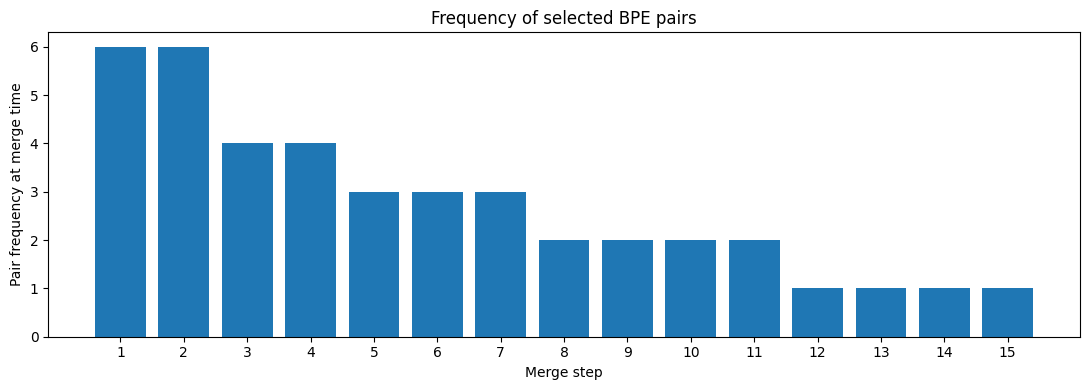

In [13]:
plt.figure(figsize=(11, 4))
plt.bar(
    merge_history["step"].astype(str),
    merge_history["frequency"]
)
plt.xlabel("Merge step")
plt.ylabel("Pair frequency at merge time")
plt.title("Frequency of selected BPE pairs")
plt.tight_layout()
plt.show()

The counts generally decrease as frequent combinations are merged, but they do not have to decrease monotonically in every possible corpus and tie-breaking situation. Each merge changes the pair counts for the next iteration.

## 11. Encode a word using the learned merges

Training BPE produces an **ordered list of merge rules**. To tokenize new text, we:

1. Start from the initial character representation.
2. Apply the learned merges in the same order.
3. Return the final symbols.

The order matters. We do not simply merge every pair at once.

In [14]:
def apply_one_learned_merge(symbols, pair):
    return merge_pair_in_sequence(symbols, pair)


def bpe_encode_word(word, merges):
    symbols = word_to_symbols(word)

    for pair in merges:
        symbols = apply_one_learned_merge(symbols, pair)

    return list(symbols)


test_words = ["low", "lower", "lowest", "newer", "wider", "slower"]

encoding_examples = pd.DataFrame({
    "word": test_words,
    "subword_tokens": [
        bpe_encode_word(word, learned_merges)
        for word in test_words
    ]
})

display(encoding_examples)

,word,subword_tokens
0,low,[low</w>]
1,lower,[lower</w>]
2,lowest,[lowest</w>]
3,newer,"[new, er</w>]"
4,wider,"[wid, er</w>]"
5,slower,"[s, lower</w>]"


### Convert subword tokens into IDs

The tokenizer's final vocabulary includes:
- The initial character symbols.
- The end-of-word marker.
- Every newly merged symbol.

We can construct a vocabulary from all symbols observed in the training representations.

In [15]:
def build_bpe_vocabulary(final_sequences, merges):
    symbols = set()

    for sequence in final_sequences.values():
        symbols.update(sequence)

    # Include symbols that may be needed as initial units.
    for pair in merges:
        symbols.add(pair[0])
        symbols.add(pair[1])
        symbols.add(pair[0] + pair[1])

    return sorted(symbols)


bpe_vocabulary = build_bpe_vocabulary(
    trained_sequences,
    learned_merges
)

bpe_token_to_id = {
    token: idx
    for idx, token in enumerate(bpe_vocabulary)
}
bpe_id_to_token = {
    idx: token
    for token, idx in bpe_token_to_id.items()
}

display(pd.DataFrame({
    "token": bpe_vocabulary,
    "token_id": [bpe_token_to_id[token] for token in bpe_vocabulary]
}))

,token,token_id
0,</w>,0
1,d,1
2,e,2
3,er,3
4,er</w>,4
5,i,5
6,l,6
7,lo,7
8,low,8
9,low</w>,9


In [16]:
def bpe_encode_to_ids(word, merges, token_to_id):
    tokens = bpe_encode_word(word, merges)
    return [token_to_id[token] for token in tokens]


word = "lower"
subword_tokens = bpe_encode_word(word, learned_merges)
subword_ids = bpe_encode_to_ids(
    word,
    learned_merges,
    bpe_token_to_id
)

print("Word:          ", word)
print("Subword tokens:", subword_tokens)
print("Token IDs:     ", subword_ids)

Word:           lower
Subword tokens: ['lower</w>']
Token IDs:      [11]


## 12. Decode BPE tokens

Our educational representation attaches `</w>` to the final token of each word. Decoding removes that marker and joins the word pieces.

For a real tokenizer, decoding also has to handle spaces, punctuation, byte sequences, and special tokens according to its own conventions.

In [17]:
def bpe_decode_word(tokens):
    combined = "".join(tokens)

    if combined.endswith(END_OF_WORD):
        combined = combined[:-len(END_OF_WORD)]

    return combined


decoded_word = bpe_decode_word(subword_tokens)

print("Original:", word)
print("Tokens:  ", subword_tokens)
print("Decoded: ", decoded_word)
print("Round trip successful:", decoded_word == word)

Original: lower
Tokens:   ['lower</w>']
Decoded:  lower
Round trip successful: True


## 13. What about words not seen during training?

A character-based starting alphabet can represent a new word if all its characters were present in the training alphabet. The learned merges may not apply, so the new word can remain split into small pieces.

This is one advantage over a strict word-level vocabulary: the tokenizer does not automatically need one unique token for every complete word.

However, our toy implementation has a limitation: if a new word contains a character absent from the training alphabet, that character will not be in the learned vocabulary. Production byte-level tokenizers address this more robustly by representing text as bytes, so every byte value can be represented.

In [18]:
training_alphabet = {
    character
    for word in word_frequencies
    for character in word
}

new_word = "slower"
unknown_characters = sorted(set(new_word) - training_alphabet)

print("Training alphabet:", sorted(training_alphabet))
print("New word:", new_word)
print("Characters not seen in training:", unknown_characters)

print("BPE segmentation:", bpe_encode_word(new_word, learned_merges))

Training alphabet: ['d', 'e', 'i', 'l', 'n', 'o', 'r', 's', 't', 'w']
New word: slower
Characters not seen in training: []
BPE segmentation: ['s', 'lower</w>']


## 14. Byte-level tokenization: why bytes matter

Text is represented digitally using encodings such as UTF-8. UTF-8 represents text as bytes. A byte has 256 possible values (0 through 255).

A byte-level tokenizer can begin from this fixed byte alphabet instead of needing every possible character to appear in the training corpus.

This helps handle:
- Unusual names.
- Rare words.
- Different writing systems.
- New character combinations.
- Arbitrary text that can be encoded as UTF-8.

This does **not** mean every byte-level tokenizer uses exactly the same algorithm or preprocessing. GPT-2-style byte-level BPE, for example, combines byte-level representation with pre-tokenization and learned merges.

In [19]:
examples = ["hello", "café", "नमस्ते", "模型"]

byte_rows = []
for item in examples:
    encoded_bytes = item.encode("utf-8")
    byte_rows.append({
        "text": item,
        "UTF-8 bytes": list(encoded_bytes),
        "byte_count": len(encoded_bytes)
    })

display(pd.DataFrame(byte_rows))

,text,UTF-8 bytes,byte_count
0,hello,"[104, 101, 108, 108, 111]",5
1,café,"[99, 97, 102, 195, 169]",5
2,नमस्ते,"[224, 164, 168, 224, 164, 174, 224, 164, 184, ...",18
3,模型,"[230, 168, 161, 229, 158, 139]",6


### A useful distinction

- **Character:** a text unit as interpreted by a programming language or Unicode processing library.
- **Code point:** a Unicode number assigned to a character.
- **Byte:** an 8-bit unit used to store or transmit encoded text.
- **Token:** a unit chosen by a tokenizer; it may represent a character, byte sequence, word fragment, whole word, or other piece.

These are not interchangeable concepts.

## 15. Vocabulary size and sequence length

Tokenizer design involves trade-offs.

- A larger vocabulary can represent common text with fewer tokens.
- A smaller vocabulary may require longer token sequences.
- Larger vocabularies increase the size of the model's input embedding and output projection matrices.
- Token count affects context-window usage and computational cost.

Let's compare character-level and word-level counts for a small corpus. Our BPE tokenizer can also be compared on words it can represent.

In [20]:
comparison_corpus = [
    "low lower lowest",
    "new newer",
    "wide wider"
]

def count_character_units(text):
    return len(text.replace(" ", ""))


def count_word_units(text):
    return len(text.split())


def count_bpe_units(text, merges):
    words = text.split()
    return sum(len(bpe_encode_word(word, merges)) for word in words)


rows = []
for sentence in comparison_corpus:
    rows.append({
        "text": sentence,
        "character_units_no_spaces": count_character_units(sentence),
        "word_units": count_word_units(sentence),
        "toy_bpe_units": count_bpe_units(sentence, learned_merges)
    })

comparison_df = pd.DataFrame(rows)
display(comparison_df)

,text,character_units_no_spaces,word_units,toy_bpe_units
0,low lower lowest,14,3,3
1,new newer,8,2,3
2,wide wider,9,2,5


This is a small demonstration, not a universal benchmark. The token counts depend on the corpus and on the merges learned. A production tokenizer is trained on a much larger and more diverse corpus.

## 16. Tokenizer design decisions in real SLMs

When studying a real SLM, the tokenizer is part of the model's design. Important details include:

### Vocabulary size
How many distinct token IDs can the tokenizer produce?

### Pre-tokenization
How is text divided into chunks before the main subword algorithm is applied? This can affect punctuation, whitespace, numbers, and language boundaries.

### Normalization
Are Unicode forms normalized? Are casing or whitespace transformations applied?

### Special tokens
Does the tokenizer define special IDs for beginning of sequence, end of sequence, padding, unknown tokens, or chat roles?

### Byte handling
Can the tokenizer represent arbitrary text, including rare or unseen characters?

### Compatibility
The model must use the same tokenizer configuration at training and inference time. Changing the tokenizer changes the meaning of token IDs and the embedding/output vocabulary.

## 17. Summary: what we learned

We now understand the core purpose of tokenization and have implemented a small BPE learner.

### Key takeaways

1. Tokenization converts text into units a model can represent as integer IDs.
2. Character-level tokenization has a small base vocabulary but often creates long sequences.
3. Word-level tokenization creates short sequences for known words but struggles with unseen words and large vocabularies.
4. Subword tokenization balances vocabulary size and sequence length.
5. BPE repeatedly merges frequent adjacent symbol pairs.
6. The ordered merge list is needed to reproduce tokenization.
7. Byte-level approaches provide a robust base representation for arbitrary text.
8. The tokenizer and model vocabulary must remain compatible.

### Knowledge check

Try answering these before moving on:

1. Why do language models use token IDs rather than raw strings?
2. What is the main weakness of word-level tokenization?
3. What does BPE merge at each training step?
4. Why are pair counts weighted by word frequency?
5. Why must the order of BPE merges be preserved?
6. How does byte-level tokenization help with unseen characters?
7. Why must a model and tokenizer be used together?

### What we deliberately did not build

Our tokenizer is not a production-ready tokenizer. It does not implement:
- GPT-style regex pre-tokenization.
- Full byte-to-Unicode handling.
- Special-token management.
- Streaming or batch-optimized encoding.
- Full Unicode normalization policies.
- A production serialization format.

That is intentional. We focused on understanding the algorithm before using a mature tokenizer library.

### Next topic

**Training Data for Small Language Models — Understanding and Preparing a Text Corpus.**

Before training a tokenizer and model for a real SLM, we need to understand where training text comes from, how corpus quality affects model behavior, and how to clean, filter, deduplicate, and prepare data.